**Week 2: Assignment 3 Script**

In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Site and sea-state parameters (table column 4, 5, 6)
g = 9.81        # gravitational acceleration [m/s^2]
h = 25.0        # water depth [m]
Hm0 = 7         # significant wave height [m]
m0 = Hm0**2/16  # zeroth spectral moment [m^2]

# JONSWAP parameters (starting assumptions) SLIDE 2 LECTURE 5
Tp = 10.0       # peak period [s]  -> s0 ≈ 0.045, steep young wind sea 
fp = 1 / Tp     # peak frequency [Hz]
gamma = 3.3     # peak enhancement factor (standard JONSWAP)

In [3]:
# Frequency axis: start just above 0 (f^-5 blows up at f = 0)
# and cut off the high-frequency tail at 5*fp
f_min = 0.01
f_max = 5 * fp
f = np.linspace(f_min, f_max, 5000)   # [Hz]

In [4]:
#SLIDE 12 LECTURE 5

def jonswap(f, Hs, Tp, gamma=3.3):
    """JONSWAP variance density spectrum E(f) [m^2/Hz], written with Hs and Tp."""
    fp = 1 / Tp

    # Pierson-Moskowitz base shape
    E_pm = (5/16) * Hs**2 * fp**4 * f**(-5) * np.exp(-1.25 * (fp / f)**4)

    # Peak width: 0.07 left of the peak, 0.09 right of it
    sigma = np.where(f <= fp, 0.07, 0.09)

    # Peak enhancement
    peak = gamma ** np.exp(-(f - fp)**2 / (2 * sigma**2 * fp**2))

    # Normalisation so that m0 = Hs^2/16 still holds
    A_gamma = 1 - 0.287 * np.log(gamma)

    return A_gamma * E_pm * peak



In [5]:
E = jonswap(f, Hm0, Tp, gamma)

m0_num = np.trapezoid(E, f)       # area under the spectrum 
Hm0_num = 4 * np.sqrt(m0_num)

print(f"m0 target   = {m0:.3f} m^2")
print(f"m0 computed = {m0_num:.3f} m^2")
print(f"Hm0 computed = {Hm0_num:.2f} m")

m0 target   = 3.062 m^2
m0 computed = 3.066 m^2
Hm0 computed = 7.00 m


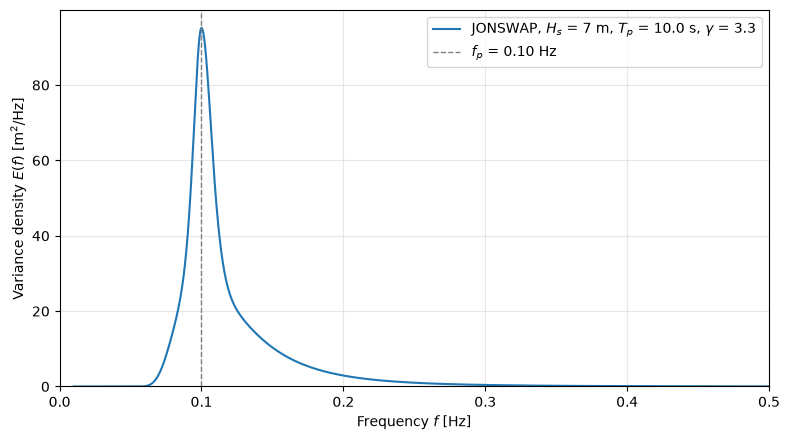

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(f, E, label=fr'JONSWAP, $H_s$ = {Hm0} m, $T_p$ = {Tp} s, $\gamma$ = {gamma}')
ax.axvline(fp, color='grey', ls='--', lw=1, label=fr'$f_p$ = {fp:.2f} Hz')
ax.set_xlabel('Frequency $f$ [Hz]')
ax.set_ylabel('Variance density $E(f)$ [m$^2$/Hz]')
ax.set_xlim(0, f_max)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('jonswap_spectrum.pdf')   # vector figure for Overleaf
plt.show()

In [7]:
#SLIDE 9 LECTURE 5

def moment(n, f, E):
    """n-th spectral moment m_n = integral of f^n E(f) df"""
    return np.trapezoid(f**n * E, f)

m_min1 = moment(-1, f, E)
m0_s   = moment(0,  f, E)
m1     = moment(1,  f, E)
m2     = moment(2,  f, E)

Tm     = np.sqrt(m0_s / m2)   # = Tm02 ≈ Tz
Tm01   = m0_s / m1
Tm_10  = m_min1 / m0_s

print(f"Tm (=Tm02) = {Tm:.2f} s (Mean zero-crossing period)")
print(f"Tm01       = {Tm01:.2f} s (Mean period)")
print(f"Tm-1,0     = {Tm_10:.2f} s (Mean wave period)")
print(f"Tp         = {Tp:.2f} s (Peak period)")

Tm (=Tm02) = 7.93 s (Mean zero-crossing period)
Tm01       = 8.39 s (Mean period)
Tm-1,0     = 9.04 s (Mean wave period)
Tp         = 10.00 s (Peak period)


In [8]:
def wave_steepness(Hm0, T):
    """Wave steepness s0 = Hm0 / (g T^2)"""
    L = 1.56 * T**2
    return Hm0 / L

steepness_Tp = wave_steepness(Hm0, Tp)

print(f"Wave steepness s_op = {steepness_Tp:.3f} (for Tp = {Tp:.2f} s)")

Wave steepness s_op = 0.045 (for Tp = 10.00 s)


**Assingment 4**

In [9]:
# --- Question 4a: random-phase synthesis (linear) ---
D  = 3600.0          # record length [s]  (1 hour)
dt = 0.25            # time step [s]     -> Nyquist 2 Hz >> f_max
df = 1 / D           # frequency resolution [Hz]; record repeats after 1/df

f_syn = np.arange(df, 5*fp + df/2, df)    # component frequencies [Hz]
t     = np.arange(0, D, dt)               # time axis [s]

In [10]:
def wavenumber(f, h, g=9.81, tol=1e-12, max_iter=50):
    """Wavenumber k from the full dispersion relation w^2 = g k tanh(kh)
    (intermediate depth), solved with Newton-Raphson (L3 appendix 2/5).
    Works for a single frequency or an array of frequencies."""
    omega = 2 * np.pi * np.asarray(f, dtype=float)
    k = omega**2 / g                                   # deep-water start value k0
    for _ in range(max_iter):
        F  = g * k * np.tanh(k * h) - omega**2         # residual of dispersion relation
        dF = g * np.tanh(k * h) + g * k * h / np.cosh(k * h)**2   # dF/dk
        k_new = k - F / dF                             # Newton-Raphson step
        if np.max(np.abs(k_new - k)) < tol:            # converged for all components
            return k_new
        k = k_new
    return k

E_syn = jonswap(f_syn, Hm0, Tp, gamma)      # spectrum on the synthesis grid
a     = np.sqrt(2 * E_syn * df)             # component amplitudes (L5 app. 2/4)
omega = 2 * np.pi * f_syn
k     = wavenumber(f_syn, h)                # intermediate depth (full dispersion relation)

rng   = np.random.default_rng(seed=42)      # fixed seed = reproducible realisation
alpha = rng.uniform(0, 2*np.pi, size=f_syn.size)   # random phases, uniform [0, 2pi)

In [11]:
z  = 0.0                                                   # evaluation depth [m]
Hu = omega * np.cosh(k * (z + h)) / np.sinh(k * h)         # u-amplitude per m of eta

eta = np.zeros_like(t)
u   = np.zeros_like(t)
for i in range(f_syn.size):
    phase = -omega[i] * t + alpha[i]       # x = 0: the k*x term is absorbed in alpha
    eta  += a[i] * np.cos(phase)
    u    += a[i] * Hu[i] * np.cos(phase)  # in phase with eta (L3 slide 16)

Hs from record  = 7.00 m   (target 7 m)
mean eta        = -6.3e-16 m (should be ~0)
u_rms record    = 1.528 m/s
u_rms spectrum  = 1.528 m/s  (sqrt of m0,u, L5 slide 15)
Tz from record  = 7.83 s   (compare Tm = Tm02)


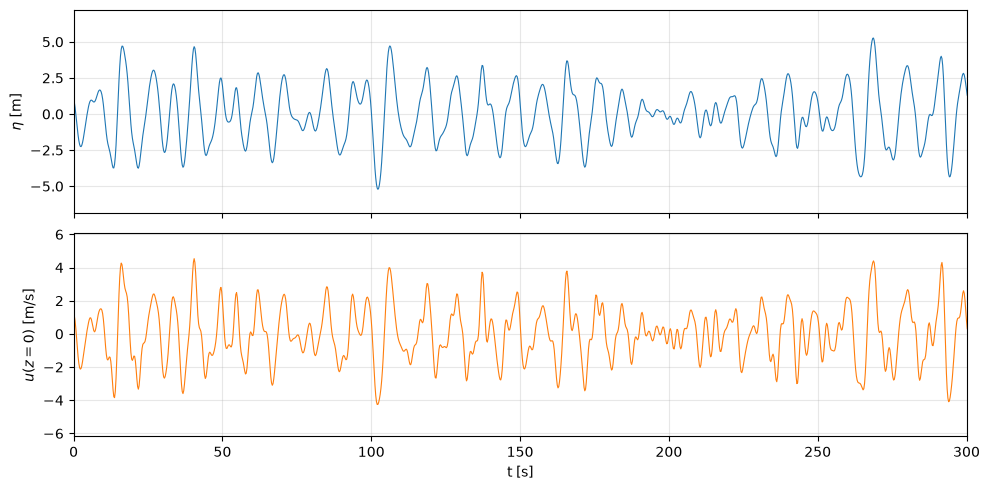

In [12]:
print(f"Hs from record  = {4*np.std(eta):.2f} m   (target {Hm0} m)")
print(f"mean eta        = {np.mean(eta):.1e} m (should be ~0)")
print(f"u_rms record    = {np.std(u):.3f} m/s")
print(f"u_rms spectrum  = {np.sqrt(np.sum((a*Hu)**2)/2):.3f} m/s  (sqrt of m0,u, L5 slide 15)")

# zero-crossing period (L5 slide 6) -> compare with your Tm from question 3
up = np.where((eta[:-1] < 0) & (eta[1:] >= 0))[0]
print(f"Tz from record  = {D/len(up):.2f} s   (compare Tm = Tm02)")

fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axs[0].plot(t, eta, lw=0.8); axs[0].set_ylabel(r'$\eta$ [m]')
axs[1].plot(t, u, lw=0.8, color='C1'); axs[1].set_ylabel(r'$u(z=0)$ [m/s]')
axs[1].set_xlabel('t [s]'); axs[1].set_xlim(0, 300)   # zoom in on 5 minutes
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [13]:
# --- Question 4b: second-order super-harmonic bound waves (narrowband, L6) ---
from scipy.signal import hilbert

def G_stokes(kh):
    """Second-order Stokes transfer function a2 / (k a^2) (L6, narrowband slide)."""
    return np.cosh(kh) * (2 + np.cosh(2*kh)) / (4 * np.sinh(kh)**3)

# Step 3: carrier wave at the spectral peak
omega_p = 2 * np.pi / Tp
kp      = wavenumber(1/Tp, h)          # dispersion relation at f_p (needs Newton-Raphson version!)
G       = G_stokes(kp * h)

# Step 2: envelope A(t) and phase theta(t) from the analytic signal
z_an  = hilbert(eta)                   # eta1 + i H[eta1]
A     = np.abs(z_an)                   # envelope (wave groups)
theta = np.angle(z_an)                 # phase of the carrier

# Step 4: super-harmonic surface elevation
eta22 = G * kp * A**2 * np.cos(2 * theta)

# Super-harmonic velocity at depth z (from phi2 of the 2nd-order Stokes solution)
Hu22 = 0.75 * omega_p * kp * np.cosh(2*kp*(z + h)) / np.sinh(kp*h)**4
u22  = Hu22 * A**2 * np.cos(2 * theta)

# Total second-order signals
eta_2nd = eta + eta22
u_2nd   = u + u22

print(f"kp*h = {kp*h:.2f},  G = {G:.3f}   (deep water: G = 0.5)")
print(f"max crest:  linear {eta.max():.2f} m  -> 2nd order {eta_2nd.max():.2f} m")
print(f"min trough: linear {eta.min():.2f} m  -> 2nd order {eta_2nd[np.argmin(eta)]:.2f} m")
print(f"mean of eta22 = {eta22.mean():.1e} m  (super-harmonic adds no mean level)")

kp*h = 1.20,  G = 0.988   (deep water: G = 0.5)
max crest:  linear 6.57 m  -> 2nd order 8.60 m
min trough: linear -6.24 m  -> 2nd order -4.44 m
mean of eta22 = 1.0e-18 m  (super-harmonic adds no mean level)


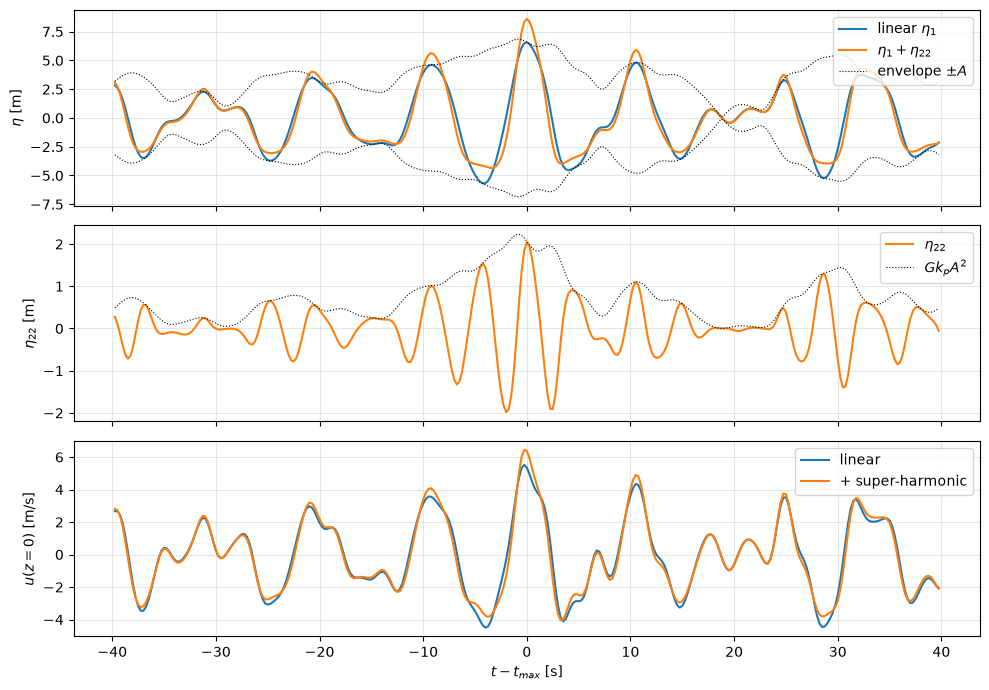

In [14]:
i_max = np.argmax(eta_2nd)
m = (t > t[i_max] - 40) & (t < t[i_max] + 40)
tt = t[m] - t[i_max]

fig, axs = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
axs[0].plot(tt, eta[m], label=r'linear $\eta_1$')
axs[0].plot(tt, eta_2nd[m], label=r'$\eta_1 + \eta_{22}$')
axs[0].plot(tt, A[m], 'k:', lw=0.8, label=r'envelope $\pm A$'); axs[0].plot(tt, -A[m], 'k:', lw=0.8)
axs[0].set_ylabel(r'$\eta$ [m]'); axs[0].legend(loc='upper right')

axs[1].plot(tt, eta22[m], color='C1', label=r'$\eta_{22}$')
axs[1].plot(tt, G*kp*A[m]**2, 'k:', lw=0.8, label=r'$G k_p A^2$')
axs[1].set_ylabel(r'$\eta_{22}$ [m]'); axs[1].legend(loc='upper right')

axs[2].plot(tt, u[m], label='linear')
axs[2].plot(tt, u_2nd[m], label='+ super-harmonic')
axs[2].set_ylabel(r'$u(z=0)$ [m/s]'); axs[2].set_xlabel(r'$t - t_{max}$ [s]'); axs[2].legend(loc='upper right')
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()